In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [9]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

D.1 Leave-one-out cross-validation

Points (-1, 0), (p, 1), (1, 0).

Constant model $h_0(x) = b_0$ (degree 0) and linear model $h_1(x) = a_1 x + b_1$ (degree 1), fitted by least squares, squared error.

---

D.1(c) `loocv(points, degree)`

In [10]:
def loocv(points, degree):
    """Leave-one-out error for polynomial regression of the given degree.
    For each point: fit np.polyfit on the other points, predict the left-out
    point, square the error. Return the average."""
    pts = np.asarray(points, dtype=float)
    errs = []
    for n in range(len(pts)):
        rest = np.delete(pts, n, axis=0)
        coef = np.polyfit(rest[:, 0], rest[:, 1], degree)
        pred = np.polyval(coef, pts[n, 0])
        errs.append((pts[n, 1] - pred) ** 2)
    return np.mean(errs), errs

def points_for(rho):
    return [(-1.0, 0.0), (rho, 1.0), (1.0, 0.0)]

Check against the hand answers from D.1(a) and D.1(b), with ρ = 2.

In [11]:
rows = []
for deg, name in [(0, "h0 constant"), (1, "h1 linear")]:
    e_cv, e_each = loocv(points_for(2.0), deg)
    rows.append({"model": name,
                 "e1 (leave out x=-1)": e_each[0],
                 "e2 (leave out x=rho)": e_each[1],
                 "e3 (leave out x=1)": e_each[2],
                 "Ecv": e_cv})
pd.DataFrame(rows).round(4)

,model,e1 (leave out x=-1),e2 (leave out x=rho),e3 (leave out x=1),Ecv
0,h0 constant,0.25,1.0,0.2500,0.5000
1,h1 linear,4.00,1.0,0.4444,1.8148


---

D.1(d) Sweep ρ over [1.1, 6]

In [12]:
rhos = np.round(np.arange(1.1, 6.0 + 1e-9, 0.01), 2)
E0 = np.array([loocv(points_for(r), 0)[0] for r in rhos])
E1 = np.array([loocv(points_for(r), 1)[0] for r in rhos])

# crossing = where the sign of E0 - E1 changes
diff = E0 - E1
idx = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]
# linear interpolation between the two grid points around each sign change
crossings = [rhos[i] - diff[i] * (rhos[i + 1] - rhos[i]) / (diff[i + 1] - diff[i]) for i in idx]
rho_exact = np.sqrt(9 + 4 * np.sqrt(6))
print("crossing(s) read from the sweep:", [round(c, 3) for c in crossings])
print(f"exact crossing sqrt(9 + 4 sqrt 6) = {rho_exact:.4f}")

crossing(s) read from the sweep: [np.float64(4.336)]
exact crossing sqrt(9 + 4 sqrt 6) = 4.3357


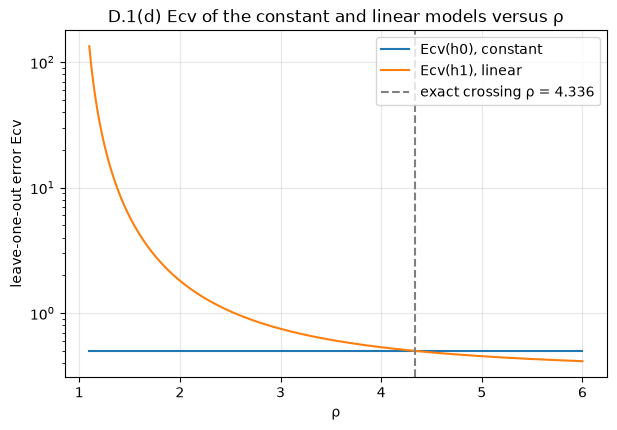

In [13]:
fig, ax = new_ax("ρ", "leave-one-out error Ecv", "D.1(d) Ecv of the constant and linear models versus ρ", logy=True)
ax.plot(rhos, E0, label="Ecv(h0), constant")
ax.plot(rhos, E1, label="Ecv(h1), linear")
ax.axvline(rho_exact, ls="--", c="gray", label=f"exact crossing ρ = {rho_exact:.3f}")
ax.legend(); fig.savefig("D1d_sweep.png", dpi=150)

In [14]:
# which model leave-one-out selects on each side of the crossing
for r in [2.0, 4.0, 4.5, 6.0]:
    e0, e1 = loocv(points_for(r), 0)[0], loocv(points_for(r), 1)[0]
    print(f"rho = {r}: Ecv(h0) = {e0:.4f}, Ecv(h1) = {e1:.4f} -> selects {'h0' if e0 < e1 else 'h1'}")

rho = 2.0: Ecv(h0) = 0.5000, Ecv(h1) = 1.8148 -> selects h0
rho = 4.0: Ecv(h0) = 0.5000, Ecv(h1) = 0.5348 -> selects h0
rho = 4.5: Ecv(h0) = 0.5000, Ecv(h1) = 0.4863 -> selects h1
rho = 6.0: Ecv(h0) = 0.5000, Ecv(h1) = 0.4139 -> selects h1
